# Домашнє завдання: Візуалізація даних з Matplotlib

## Опис завдання
У цьому домашньому завданні ви продовжите працювати з датасетом про оренду велосипедів `yulu_rental.csv`, але тепер будете використовувати бібліотеку Matplotlib для створення більш складних та налаштованих візуалізацій.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---


🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Завантаження даних
df = pd.read_csv('/content/yulu_rental.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додаткові колонки
df['month'] = df.index.month
df['hour'] = df.index.hour
df['weekday'] = df.index.day_name()
df['weekday_num'] = df.index.weekday
df['week'] = df.index.isocalendar().week
df['year'] = df.index.year
df['day'] = df.index.day

## Завдання 1: Порівняння Pandas vs Matplotlib

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно впродовж всього періоду в даних двома способами:
1. Використовуючи Pandas (DataFrame.plot())
2. Використовуючи Matplotlib безпосередньо

В обох методах додайте маркери-кружечки. Можна також задати свій відмінний від стандартного колір.

Підказка: отримати потрібний формат даних найзручніше з методом датафрейму `resample`.

**Опишіть свої спостереження:** чим відрізняються 2 побудованих графіки? Який вам більше подобається?

In [2]:
df.head(2)

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,month,hour,weekday,weekday_num,week,year,day
datetime,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,1,0,Saturday,5,52,2011,1
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,1,1,Saturday,5,52,2011,1


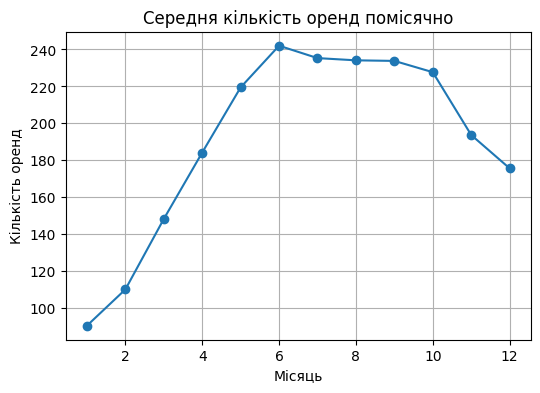

In [3]:
avg_count_monthly = df.groupby('month')['count'].mean()
avg_count_monthly.plot(
    marker= 'o',
    figsize= (6, 4),
    title = 'Середня кількість оренд помісячно',
    xlabel='Місяць',
    ylabel='Кількість оренд',
    grid=True
);

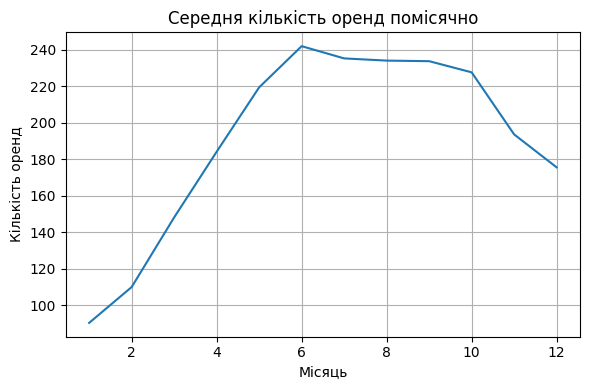

In [4]:
plt.figure(figsize=(6, 4))
plt.plot(avg_count_monthly.index, avg_count_monthly.values)
plt.title('Середня кількість оренд помісячно')
plt.xlabel('Місяць')
plt.ylabel('Кількість оренд')
plt.tight_layout()
plt.grid(True)
plt.show()


Обидва графіки показують однакові дані, тому сильно не відрізняються. Мені більше подобається графік через Pandas, бо він простіший і зрозуміліший.

## Завдання 2: Робота зі списками та numpy

**Завдання:**
Вам задані 3 списки:
1. Номер дня тижня.
2. Продажі в тиждень 1.
3. Продажі в тиждень 2.

Створіть графік, на якому лінійними графіками різних кольорів накладено продажі за обидва тижні.

Обовʼязково додайте назву графіку, підписи вісям ОХ, ОУ, назви кожного з рядів даних, легенду.

**Дайте відповіді на питання**
1. Судячи з графіку, в який тиждень проодажі були стабільніше?
2. Чи можете ви підкріпити свій висновок обчисленнями? Якими саме? Можна (але не обовʼязково) навести ці обчислення.

In [5]:
# Дані у вигляді списків
days = [1, 2, 3, 4, 5, 6, 7] # 1 - це понеділок
sales_week1 = [1349,1562,1600,1606,1510,959,822]  # Продажі за тиждень1
sales_week2 = [1321,1263,1162,1406,1421,1248,1204]  # Продажі за тиждень1

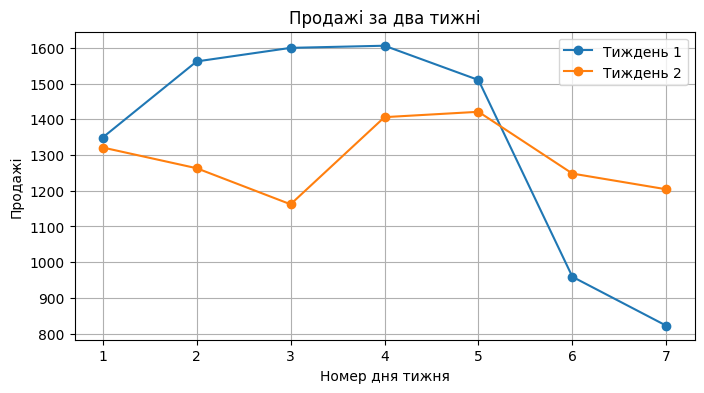

In [6]:
plt.figure(figsize=(8, 4))

plt.plot(days, sales_week1, label='Тиждень 1', marker='o')
plt.plot(days, sales_week2, label='Тиждень 2', marker='o')

plt.title('Продажі за два тижні')
plt.xlabel('Номер дня тижня')
plt.ylabel('Продажі')
plt.legend()
plt.grid(True)

plt.show()

In [7]:
std_week1 = np.std(sales_week1)
std_week2 = np.std(sales_week2)

print(f"Стандартне відхилення Тиждень 1: {std_week1}")
print(f"Стандартне відхилення Тиждень 2: {std_week2}")

Стандартне відхилення Тиждень 1: 299.99857142517004
Стандартне відхилення Тиждень 2: 90.9060964256355


Стабільнішими були продажі у 2-й тиждень, бо графік має менші коливання.

Продажі в 1 тиждень були стабільнішими, оскільки їх стандартне відхилення менше порівняно з 2 тижнем, що означає мінімальні коливання значень навколо середнього.

## Завдання 3: Subplot - 2x2 сітка графіків

**Завдання:**
Створіть сітку 2x2 з чотирма різними графіками, використовуючи `plt.subplot()`:
1. Лінійний графік середньої температури помісячно.
2. Стовпчикова діаграма середньої годинної кількості оренд за кварталами.
3. Гістограма вологості за всіма погодинними вимірами.
4. Scatter plot температури vs кількості оренд.

Кожен підграфік має містити всі необхідні підписи. Дашборд має містити назву.

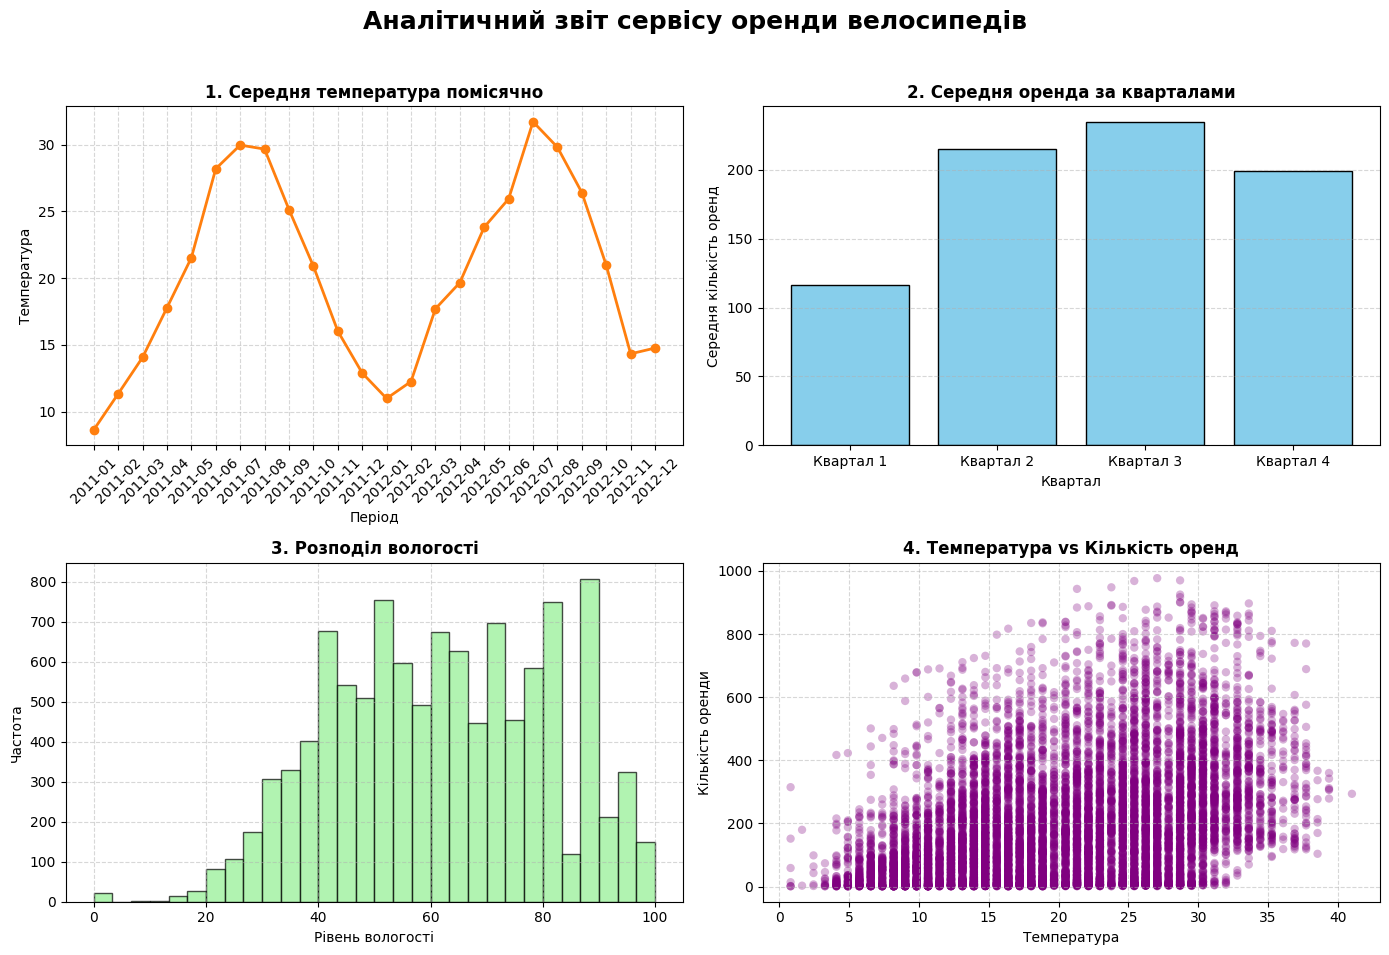

In [8]:
fig = plt.figure(figsize=(14, 10))
fig.suptitle('Аналітичний звіт сервісу оренди велосипедів', fontsize=18, fontweight='bold', y=0.95)

monthly_temp = df.groupby(['year', 'month'])['temp'].mean().reset_index()
x_labels = [f"{int(y)}-{int(m):02d}" for y, m in zip(monthly_temp['year'], monthly_temp['month'])]

plt.subplot(2, 2, 1)
plt.plot(range(len(monthly_temp)), monthly_temp['temp'], marker='o', color='tab:orange', linewidth=2)
plt.xticks(range(len(monthly_temp)), x_labels, rotation=45)
plt.title('1. Середня температура помісячно', fontsize=12, fontweight='bold')
plt.xlabel('Період', fontsize=10)
plt.ylabel('Температура', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

if 'quarter' not in df.columns:
    df['quarter'] = df['month'].apply(lambda m: (int(m)-1)//3 + 1)
quarterly_rentals = df.groupby('quarter')['count'].mean()

plt.subplot(2, 2, 2)
plt.bar([f'Квартал {q}' for q in quarterly_rentals.index], quarterly_rentals.values, color='skyblue', edgecolor='black')
plt.title('2. Середня оренда за кварталами', fontsize=12, fontweight='bold')
plt.xlabel('Квартал', fontsize=10)
plt.ylabel('Середня кількість оренд', fontsize=10)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

hum_col = 'humidity' if 'humidity' in df.columns else 'hum'
plt.subplot(2, 2, 3)
plt.hist(df[hum_col].dropna(), bins=30, color='lightgreen', edgecolor='black', alpha=0.7)
plt.title('3. Розподіл вологості', fontsize=12, fontweight='bold')
plt.xlabel('Рівень вологості', fontsize=10)
plt.ylabel('Частота', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(2, 2, 4)
plt.scatter(df['temp'], df['count'], alpha=0.3, color='purple', edgecolors='none')
plt.title('4. Температура vs Кількість оренд', fontsize=12, fontweight='bold')
plt.xlabel('Температура', fontsize=10)
plt.ylabel('Кількість оренди', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('bike_dashboard_2x2.png', dpi=300)
plt.show()

## Завдання 4: Subplots - об'єктно-орієнтований підхід

**Завдання:**
Створіть той самий набір графіків, але використовуючи `fig, ax = plt.subplots()`.

**Дайте відповідь на питання своїми словами**
- Чим відрізняється підхід побудови кількох графіків на одній фігурі з `plt.subplots()` від `plt.subplot()`?

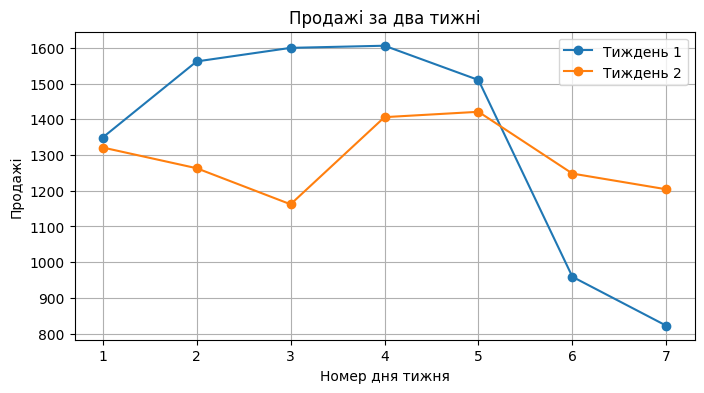

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(days, sales_week1, label='Тиждень 1', marker='o')
ax.plot(days, sales_week2, label='Тиждень 2', marker='o')
ax.set_title('Продажі за два тижні')
ax.set_xlabel('Номер дня тижня')
ax.set_ylabel('Продажі')
ax.legend()
ax.grid(True)
plt.show()

plt.subplots() створює всю фігуру та всі осі одразу однією командою (fig, ax), дозволяє налаштувати кожен графік через виклики методів конкретного об'єкта.
plt.subplot() активує поточний підграфік за індексом на кожному кроці, що робить код менш структурованим при великій кількості графіків

## (Опціонально) Завдання 5: Тонкі налаштування форматування графіка

**Завдання:**
Подібно до прикладу, наведеного в лекції, створіть професійно оформлений графік помісячної динаміки оренди з максимальною кількістю деталей та налаштувань. Ваш графік має включати:

**Обов'язкові елементи:**
1. **Три лінії:** середнє, максимум, мінімум за місяцями
2. **Різні стилі ліній:** суцільна, пунктирна, крапкова + різні маркери
3. **Заливка області** між мінімумом та максимумом
4. **Дві анотації:** для найвищого та найнижчого середнього значення
5. **Горизонтальна лінія** середнього за весь рік
6. **Двошарова сітка:** основна та допоміжна
7. **Стилізована легенда** з тінню
8. **Текстовий блок** зі статистикою в кутку графіка
9. **Професійне оформлення:** заголовки, підписи осей з жирним шрифтом

**Результат:** Графік повинен виглядати як готова ілюстрація для бізнес-звіту або наукової публікації.

Приклад очікуваного результату.
![](https://drive.google.com/uc?id=1YoJByivzlqncEF2zbWu3EhGSZ7XRme8T)


**Питання для інтерпретації:**
1. Яка перевага додавання анотацій на графік?
2. Для чого використовується fill_between()?
3. Як текстовий блок допомагає в інтерпретації даних?

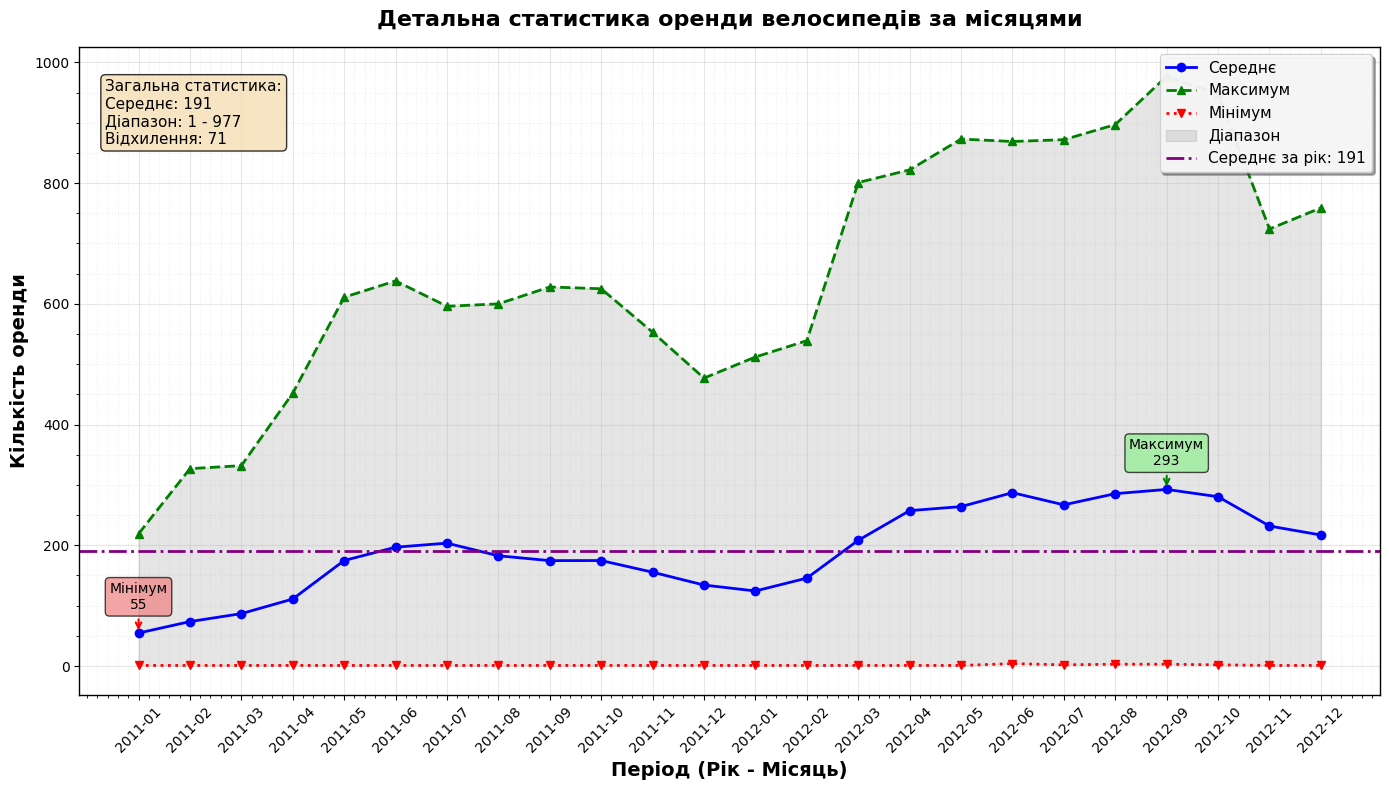

In [10]:
monthly_stats = df.groupby(['year', 'month'])['count'].agg(['mean', 'max', 'min'])
monthly_stats = monthly_stats.rename(columns={'mean': 'Середнє', 'max': 'Максимум', 'min': 'Мінімум'})

x_labels = [f"{int(y)}-{int(m):02d}" for y, m in monthly_stats.index]

ax = monthly_stats[['Середнє', 'Максимум', 'Мінімум']].plot(
    style=['bo-', 'g^--', 'rv:'],
    linewidth=2,
    figsize=(14, 8)
)

ax.fill_between(
    range(len(monthly_stats)),
    monthly_stats['Мінімум'],
    monthly_stats['Максимум'],
    alpha=0.2,
    color='gray',
    label='Діапазон'
)

max_idx = monthly_stats['Середнє'].argmax()
max_val = monthly_stats['Середнє'].max()
ax.annotate(
    f'Максимум\n{max_val:.0f}',
    xy=(max_idx, max_val),
    xytext=(max_idx, max_val + 40),
    arrowprops=dict(arrowstyle='->', color='green', lw=1.5),
    fontsize=10,
    ha='center',
    bbox=dict(boxstyle="round,pad=0.3", facecolor='lightgreen', alpha=0.7)
)

min_idx = monthly_stats['Середнє'].argmin()
min_val = monthly_stats['Середнє'].min()
ax.annotate(
    f'Мінімум\n{min_val:.0f}',
    xy=(min_idx, min_val),
    xytext=(min_idx, min_val + 40),
    arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
    fontsize=10,
    ha='center',
    bbox=dict(boxstyle="round,pad=0.3", facecolor='lightcoral', alpha=0.7)
)

ax.set_xticks(range(len(monthly_stats)))
ax.set_xticklabels(x_labels, rotation=45)

ax.set_xlabel('Період (Рік - Місяць)', fontsize=14, fontweight='bold')
ax.set_ylabel('Кількість оренди', fontsize=14, fontweight='bold')
ax.set_title('Детальна статистика оренди велосипедів за місяцями', fontsize=16, fontweight='bold', pad=15)

ax.grid(True, which='major', linestyle='-', alpha=0.3)
ax.grid(True, which='minor', linestyle=':', alpha=0.2)
ax.minorticks_on()

overall_mean = monthly_stats['Середнє'].mean()
ax.axhline(
    y=overall_mean,
    color='purple',
    linestyle='-.',
    linewidth=2,
    label=f'Середнє за рік: {overall_mean:.0f}'
)

ax.legend(loc='upper right', fontsize=11, frameon=True, shadow=True, fancybox=True, framealpha=0.9)

textstr = f'Загальна статистика:\n'
textstr += f'Середнє: {overall_mean:.0f}\n'
textstr += f'Діапазон: {monthly_stats["Мінімум"].min():.0f} - {monthly_stats["Максимум"].max():.0f}\n'
textstr += f'Відхилення: {monthly_stats["Середнє"].std():.0f}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(
    0.02, 0.95, textstr,
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment='top',
    bbox=props
)

for spine in ax.spines.values():
    spine.set_linewidth(1)

plt.tight_layout()
plt.show()

Перевагою анотацій є те, що вони привертають увагу до ключових точок без необхідності шукати їх самостійно.

Призначення fill_between(). Візуально виділяє діапазон показуючи розкид даних навколо тренду.

Роль текстового блоку.Надає зведену статистику в одному місці та спрощує загальну оцінку без аналізу кожної точки окремо.